# 0. Classical visit-process baselines

We first model **when visits occur**, using simple Poisson and exponential Hawkes processes. A small MLP shares statistical strength across training patients by mapping each patient's **baseline** covariates \(x_i\) to constant process parameters. It does not consume subsequent covariate updates. Hawkes uses earlier events directly; these baselines do not learn a Transformer history representation.

All times below are **years since entry**. Hidden pre-entry events are excluded; excitation starts at zero at entry. Each likelihood includes the final interval with no event.

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from lifetime_clinical.tutorials.experiments import load_toy,tpp_data
from lifetime_clinical.data.synthetic import YEAR_DAYS
from lifetime_clinical.models.tpp.classical import (
    CovariatePointProcess,fit_patient_poisson,fit_patient_hawkes,
    baseline_comparison,plot_baseline_intensities)
FAST_MODE=True
EPOCHS=5 if FAST_MODE else 10
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
DATA_DIR=ROOT/'data'/('toy' if FAST_MODE else 'synthetic')
if DEVICE=='cpu': torch.set_num_threads(1)
dataset,splits,pre=load_toy(DATA_DIR)
data=tpp_data(dataset,splits,pre,dynamic=False)
print('Patients:',{k:len(v) for k,v in data.items()},'epochs:',EPOCHS,'device:',DEVICE)


Patients: {'train': 100, 'validation': 20, 'test': 10} epochs: 5 device: cpu


## Homogeneous Poisson: patient fit and cohort MLP

A constant intensity gives independent exponential waiting times:
\[
\lambda_i(t)=\lambda_i,\qquad
\ell_i=N_i\log\lambda_i-\lambda_i T_i.
\]
For an individual prefix, the maximum-likelihood estimate is \(\widehat\lambda_i=N_i/T_i\) (a numerical floor of \(10^{-6}\)/year avoids a zero rate). Across the cohort, we instead learn
\[
\lambda_i=\operatorname{softplus}(g_\theta(x_i))+10^{-6}.
\]
The MLP fits **all training patients**, selects its checkpoint using validation patients and generalises to test patients. Individual models fit only each test patient's first 60% of follow-up; all comparisons score the remaining 40%. These differ in training scope, so the comparison measures practical forecasting performance, not a controlled parameter-count experiment.

In [2]:
fraction=.6
cutoffs={s.patient_id:fraction*s.end/YEAR_DAYS for s in data['test']}
poisson_params={s.patient_id:fit_patient_poisson(s,cutoffs[s.patient_id]) for s in data['test']}
poisson_mlp=CovariatePointProcess(len(data['train'][0].static),'poisson').fit(
    data['train'],data['validation'],epochs=EPOCHS,device=DEVICE)
display(pd.DataFrame([{'Patient':s.patient_id,'Patient rate (events/year)':poisson_params[s.patient_id][0][0],
                      'MLP rate (events/year)':float(poisson_mlp.parameters_for(s)[0][0])}
                     for s in data['test']]).set_index('Patient'))


,Patient rate (events/year),MLP rate (events/year)
Patient,,
P000039,2.648374,1.981739
P000177,0.938125,2.100830
P000189,4.649234,2.373541
P000339,1.302736,2.301189
P000525,1.806576,2.134986
P000752,3.475606,2.400532
P000908,2.749047,2.161340
P000961,2.856555,2.130574
P000995,0.370878,2.144244


## Exponential Hawkes: patient fit and cohort MLP

Earlier visits increase the conditional intensity, then their effect decays:
\[
\lambda_i(t)=\mu_i+\sum_{t_j<t}\alpha_i e^{-\delta_i(t-t_j)}.
\]
We fit \((\mu_i,\alpha_i,\delta_i)\) to each patient's observed prefix by constrained maximum likelihood. The cohort variant outputs these parameters from \(g_\theta(x_i)\), with \(\mu_i,\delta_i>0\) and \(\alpha_i/\delta_i<0.95\) to keep excitation stable. Both use the same analytical likelihood:
\[
\ell_i=\sum_j\log\lambda_i(t_j)-\int_0^{T_i}\lambda_i(t)\,dt.
\]
For held-out scoring, integrate only after the cutoff but retain excitation from prefix events. Subsequent held-out events update history as they occur: this is a sequential predictive score, not a forecast that knows future visits.

In [3]:
hawkes_params={s.patient_id:fit_patient_hawkes(s,cutoffs[s.patient_id]) for s in data['test']}
hawkes_mlp=CovariatePointProcess(len(data['train'][0].static),'hawkes').fit(
    data['train'],data['validation'],epochs=EPOCHS,device=DEVICE)
rows=[]
for s in data['test']:
    for label,params in [('Patient fit',hawkes_params[s.patient_id]),('Cohort MLP',hawkes_mlp.parameters_for(s))]:
        mu,alpha,delta=params
        rows.append({'Patient':s.patient_id,'Fit':label,'mu (events/year)':float(mu[0]),
                     'alpha (events/year)':float(alpha.reshape(-1)[0]),'delta (1/year)':float(delta)})
display(pd.DataFrame(rows).set_index(['Patient','Fit']))


mu (events/year)  alpha (events/year)  delta (1/year)
Patient Fit                                                               
P000039 Patient fit          2.648316         2.319477e-05        0.006738
        Cohort MLP           0.925110         5.521255e-01        0.776848
P000177 Patient fit          0.852378         3.268163e-02        0.034413
        Cohort MLP           0.740158         7.117123e-01        1.053151
P000189 Patient fit          4.432746         1.754992e-02        0.040217
        Cohort MLP           0.856716         7.528281e-01        1.013410
P000339 Patient fit          1.136422         1.437060e-01        0.862945
        Cohort MLP           1.234995         3.937467e-01        0.606280
P000525 Patient fit          1.184661         5.826486e-01        0.613520
        Cohort MLP           0.756246         7.197154e-01        1.062303
P000752 Patient fit          3.475606         3.932917e-08        0.006738
        Cohort MLP           1.012372         7.236779e-01        1.005152
P000908 Patient fit          2.680918         3.284280e-01       11.902857
        Cohort MLP           1.029512         5.746258e-01        0.867842
P000961 Patient fit          1.568324         1.299077e+00        2.810768
        Cohort MLP           0.754167         7.188709e-01        1.061199
P000995 Patient fit          0.370878         2.462646e-07        0.006738
        Cohort MLP           1.021529         5.700953e-01        0.860339
P001201 Patient fit          1.887021         1.171911e-01        0.123400
        Cohort MLP           0.990311         3.361111e-01        0.564366

## Marked Hawkes with cohort MLP

Now each visit type \(k\) has its own intensity, and a previous type \(l\) can excite it:
\[
\lambda_{i,k}(t)=\mu_{i,k}+\sum_{t_j<t}\alpha_{i,k,m_j}e^{-\delta_i(t-t_j)}.
\]
The small MLP predicts three baselines, a \(3\times3\) excitation matrix and a shared decay for each patient. Column sums of \(\alpha_i/\delta_i\) are constrained below 0.95. The joint time/mark likelihood is
\[
\ell_i=\sum_j\log\lambda_{i,m_j}(t_j)-\int_0^{T_i}\sum_k\lambda_{i,k}(t)\,dt.
\]
Thus mark probabilities at an event time are \(\lambda_{i,k}(t)/\sum_l\lambda_{i,l}(t)\); timing and marks interact through history.

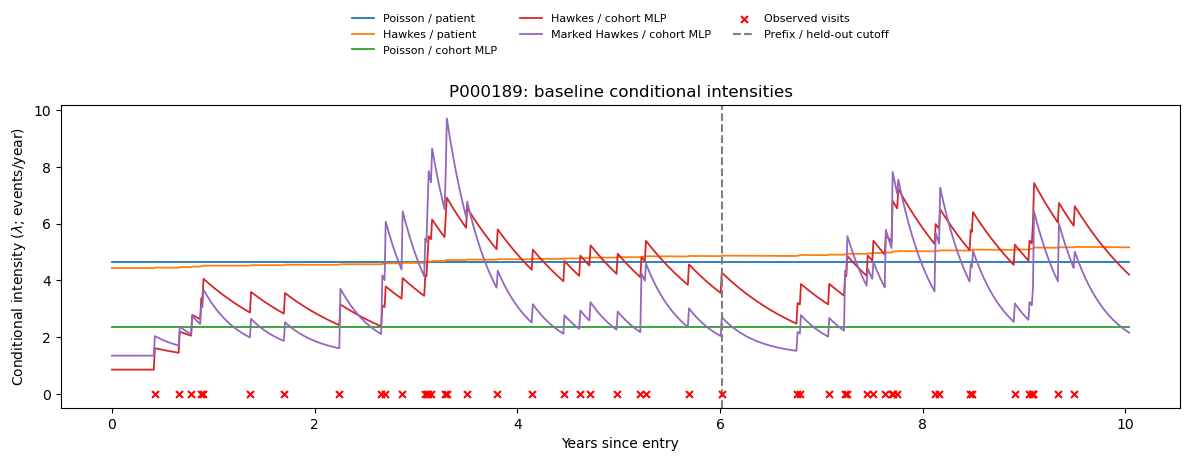

In [4]:
marked_mlp=CovariatePointProcess(len(data['train'][0].static),'marked_hawkes').fit(
    data['train'],data['validation'],epochs=EPOCHS,device=DEVICE)
models={'Poisson / cohort MLP':poisson_mlp,'Hawkes / cohort MLP':hawkes_mlp,
        'Marked Hawkes / cohort MLP':marked_mlp}
seq=max(data['test'],key=lambda s:len(s.times))
fitted={'Poisson / patient':poisson_params[seq.patient_id],
        'Hawkes / patient':hawkes_params[seq.patient_id],
        **{name:model.parameters_for(seq) for name,model in models.items()}}
fig,ax=plt.subplots(figsize=(12,4.8))
plot_baseline_intensities(seq,fitted,cutoffs[seq.patient_id],ax)
fig.tight_layout();plt.show()


## Compare NLL only for matched targets

The first column scores **visit times**, summing marked intensities when needed. All five models score exactly the same test patients, held-out intervals and censoring exposure. The second scores **times and marks**: unmarked models receive the same independent mark-probability adapter, estimated exclusively from training marks with 0.5 pseudocount smoothing. This creates valid marked extensions without changing their timing fits.

Lower NLL is better **within a column**. Timing-only and time-plus-mark NLLs are different targets and must not be compared to one another. These scores also cannot be directly ranked against TPP-A/B/C notebook scores: those use different windows/targets and a day-based time density. GP likelihoods concern physiological values, not visits.

The last cell collects all five baselines. Five fast-mode epochs and four test patients provide a smoke test, not reliable evidence of superiority.

In [5]:
counts=np.bincount(np.concatenate([s.marks for s in data['train']]),minlength=3)+.5
mark_probabilities=counts/counts.sum()
baseline_nll_comparison=baseline_comparison(data['test'],poisson_params,hawkes_params,models,mark_probabilities,fraction)
display(baseline_nll_comparison)


,Timing NLL (nats/patient),Timing + marks NLL (nats/patient)
Model,,
Poisson / patient,0.453101,7.242470
Hawkes / patient,0.202799,6.992168
Poisson / cohort MLP,1.537045,8.326415
Hawkes / cohort MLP,0.361878,7.151248
Marked Hawkes / cohort MLP,0.667260,7.657266
